In [ ]:
import gpm
import gpm.bucket
import polars as pl

from pmw_analysis.constants import DIR_BUCKET, EXTENTS_SUBSET, TC_COLUMNS, VARIABLE_SURFACE_TYPE_INDEX, COLUMN_LON, COLUMN_LAT

dfs = []
for idx, (box, extent) in enumerate(EXTENTS_SUBSET.items()):
    df_box = gpm.bucket.read(bucket_dir=DIR_BUCKET, columns=TC_COLUMNS + [COLUMN_LON, COLUMN_LAT, VARIABLE_SURFACE_TYPE_INDEX],
                             extent=extent)
    # Box index: position of the box in EXTENTS_SUBSET, as in metric.py
    dfs.append(df_box.with_columns(pl.lit(idx).alias("box")))
    print(f"{box}: {df_box.height} observations")
df = pl.concat(dfs)


In [ ]:
import pathlib
import pickle

from pmw_analysis.constants import ArgTransform
from pmw_analysis.preprocessing.aggregation_defaults import build_default_per_column_aggregations
from pmw_analysis.preprocessing.script_new_quantize_merge import _replace_special_missing_values_with_null
from pmw_analysis.preprocessing.transforms import get_transformation_function
from quantization.aggregation import AggregationPlan, AggMean
from quantization.api import quantize
from quantization.config import QuantizationConfig

DIR_B2 = pathlib.Path("/ltenas8/data/PMW_Analysis/summary_2026/b2/factor2/new/v5/all")

transform = get_transformation_function(ArgTransform.V5)
feature_columns = transform(TC_COLUMNS)

# Steps and clip ranges of the B2 quantization
with open(DIR_B2 / "quantization_config.pkl", "rb") as file:
    quant_column_configs = pickle.load(file)["quant_column_configs"]
config = QuantizationConfig(
    quant_column_configs=quant_column_configs,
    agg_plan=AggregationPlan(
        per_column={VARIABLE_SURFACE_TYPE_INDEX: build_default_per_column_aggregations()[VARIABLE_SURFACE_TYPE_INDEX]},
        default_non_quant=AggMean(),
    ),
    output_dir=DIR_B2,  # unused by quantize()
)

# As the B2 quantization: transform, then NaN and special missing values (-99, -9999) to null
df_features = transform(df.select(TC_COLUMNS + [VARIABLE_SURFACE_TYPE_INDEX]))
df_features = _replace_special_missing_values_with_null(df_features.fill_nan(None))
df_quant = quantize(df_features, config)
print(f"{df_quant.height} signatures, {df_quant['__count'].sum()} observations")


In [2]:
import pathlib

import polars as pl

import sys
sys.path.insert(0, "/home/streltso/git/pmw-analysis/src")

from pmw_analysis.constants import TC_COLUMNS, VARIABLE_SURFACE_TYPE_INDEX, ArgTransform
from pmw_analysis.preprocessing.transforms import get_transformation_function
from quantization.constants import COLUMN_COUNT, COLUMN_SUFFIX_QUANT

DIR_B2 = pathlib.Path("/ltenas8/data/PMW_Analysis/summary_2026/b2/factor2/new/v5/all")
feature_columns = get_transformation_function(ArgTransform.V5)(TC_COLUMNS)

df_b2 = pl.read_parquet(DIR_B2 / "final.parquet",
                        columns=[f"{col}{COLUMN_SUFFIX_QUANT}" for col in feature_columns]
                                + [f"{VARIABLE_SURFACE_TYPE_INDEX}__valuecounts", COLUMN_COUNT])
# Cast before summing: the sum of the UInt32 counts overflows
print(f"{df_b2.height} signatures, {df_b2[COLUMN_COUNT].cast(pl.UInt64).sum()} observations")


3062913 signatures, 21900988866 observations


In [4]:
from collections.abc import Sequence

from quantization.constants import STRUCT_FIELD_COUNT

COLUMN_VALUE_COUNTS = f"{VARIABLE_SURFACE_TYPE_INDEX}__valuecounts"


def unify_surface_types(df: pl.DataFrame, groups: Sequence[Sequence[int]] = (), suffix: str = "_unified") -> pl.DataFrame:
    """
    Add the surface-type value counts with each group of surface types counted as one type, labelled by the group's
    first index, as column f"{COLUMN_VALUE_COUNTS}{suffix}". Surface types in no group are kept as they are.
    """
    mapping = {st: group[0] for group in groups for st in group}
    column_out = f"{COLUMN_VALUE_COUNTS}{suffix}"
    counts = (
        df.select(pl.int_range(pl.len()).alias("row"), COLUMN_VALUE_COUNTS)
        .explode(COLUMN_VALUE_COUNTS, empty_as_null=True)
        .unnest(COLUMN_VALUE_COUNTS)
        .with_columns(pl.col(VARIABLE_SURFACE_TYPE_INDEX).replace(mapping))
        .group_by("row", VARIABLE_SURFACE_TYPE_INDEX)
        .agg(pl.col(STRUCT_FIELD_COUNT).sum())
        .sort("row", VARIABLE_SURFACE_TYPE_INDEX, nulls_last=True)
        .group_by("row", maintain_order=True)
        .agg(pl.struct(VARIABLE_SURFACE_TYPE_INDEX, STRUCT_FIELD_COUNT).alias(column_out))
    )
    assert counts.height == df.height
    return df.with_columns(counts[column_out])


def bcubed(df: pl.DataFrame, cluster_col: str, reference_col: str) -> tuple[float, float, float]:
    """
    B-Cubed from rows of (cluster, reference class, number of observations), as in b4_signature_scores.py.
    """
    # Cast before summing: the sum of UInt32 counts overflows
    s = df.group_by(cluster_col, reference_col).agg(pl.col("n").cast(pl.Float64).sum()).with_columns(
        pl.col("n").sum().over(cluster_col).alias("n_cluster"), pl.col("n").sum().over(reference_col).alias("n_ref"))
    n = s["n"].sum()
    precision = (s["n"] ** 2 / s["n_cluster"]).sum() / n
    recall = (s["n"] ** 2 / s["n_ref"]).sum() / n
    return precision, recall, 2 * precision * recall / (precision + recall)

In [5]:
# 1-2. Signatures without null features
quant_columns = [f"{col}{COLUMN_SUFFIX_QUANT}" for col in feature_columns]
df_b2_non_null = df_b2.drop_nulls(quant_columns)
print(f"{df_b2_non_null.height}/{df_b2.height} signatures without null features")

3055815/3062913 signatures without null features


In [13]:
from pmw_analysis.constants import ST_COLUMNS

GROUPS_BY_NAME = [
    ["Ocean", "Ocean or water Coast", "Sea-ice edge"],
    ["High vegetation", "Medium vegetation", "Low vegetation", "Mountain rain", "Standing Water", "Land coast"],
    ["Sparse vegetation", "Desert"],
    ["Elevated snow cover", "High snow cover", "Moderate snow cover", "Light snow cover", "Mountain snow"],
]

# Surface type ids are 1-based positions in ST_COLUMNS
groups = [[ST_COLUMNS.index(name) + 1 for name in group] for group in GROUPS_BY_NAME]
ids = [st for group in groups for st in group]
assert len(ids) == len(set(ids)), "a surface type is in more than one group"
print(groups)
# [[1, 13, 16], [3, 4, 5, 17, 12, 15], [6, 7], [8, 9, 10, 11, 18]]

suffix = "_unified"
df_b2_non_null = unify_surface_types(df_b2_non_null, groups=groups, suffix=suffix)

[[1, 13, 16], [3, 4, 5, 17, 12, 15], [6, 7], [8, 9, 10, 11, 18]]


In [14]:
# 4. Cluster of a signature (and of all its observations): its most frequent unified surface type
counts_unified = pl.col(f"{COLUMN_VALUE_COUNTS}{suffix}")
df_b2_non_null = df_b2_non_null.with_columns(
    counts_unified.list.get(counts_unified.list.eval(pl.element().struct.field(STRUCT_FIELD_COUNT)).list.arg_max())
    .struct.field(VARIABLE_SURFACE_TYPE_INDEX).alias("cluster")
)

In [15]:
# 5. B-Cubed against the initial surface types: one row per (signature, initial surface type) with its count
rows = (
    df_b2_non_null.select("cluster", COLUMN_VALUE_COUNTS)
    .explode(COLUMN_VALUE_COUNTS, empty_as_null=True)
    .unnest(COLUMN_VALUE_COUNTS)
    .rename({STRUCT_FIELD_COUNT: "n"})
    .filter(pl.col("n") > 0)
)
precision, recall, f1 = bcubed(rows, "cluster", VARIABLE_SURFACE_TYPE_INDEX)
print(f"P = {precision:.4f}, R = {recall:.4f}, F1 = {f1:.4f}")


P = 0.7070, R = 0.9089, F1 = 0.7953


P (cluster = signature): 0.7511
P (cluster = most frequent type), from the confusion: 0.7310


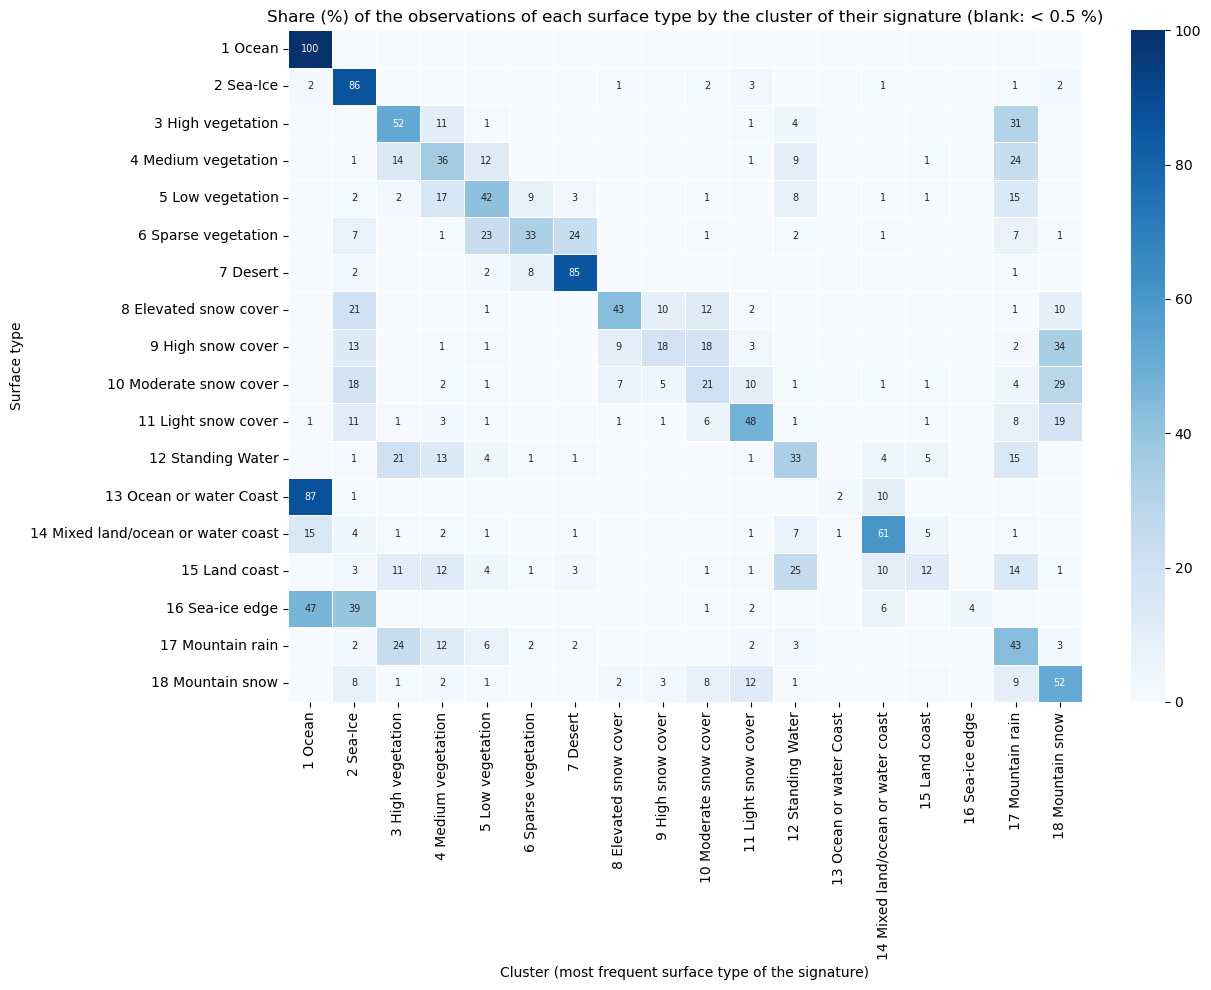

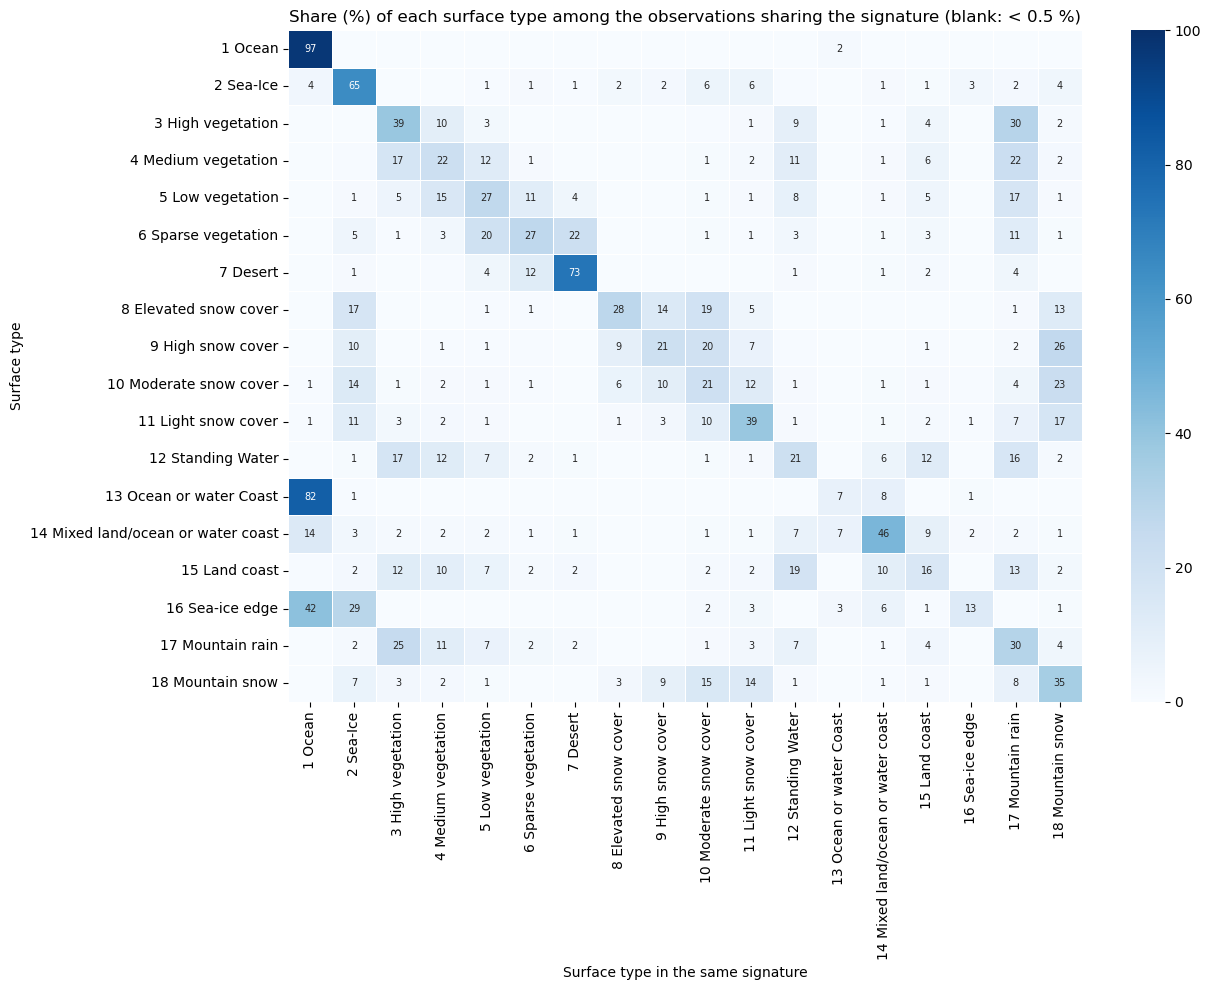

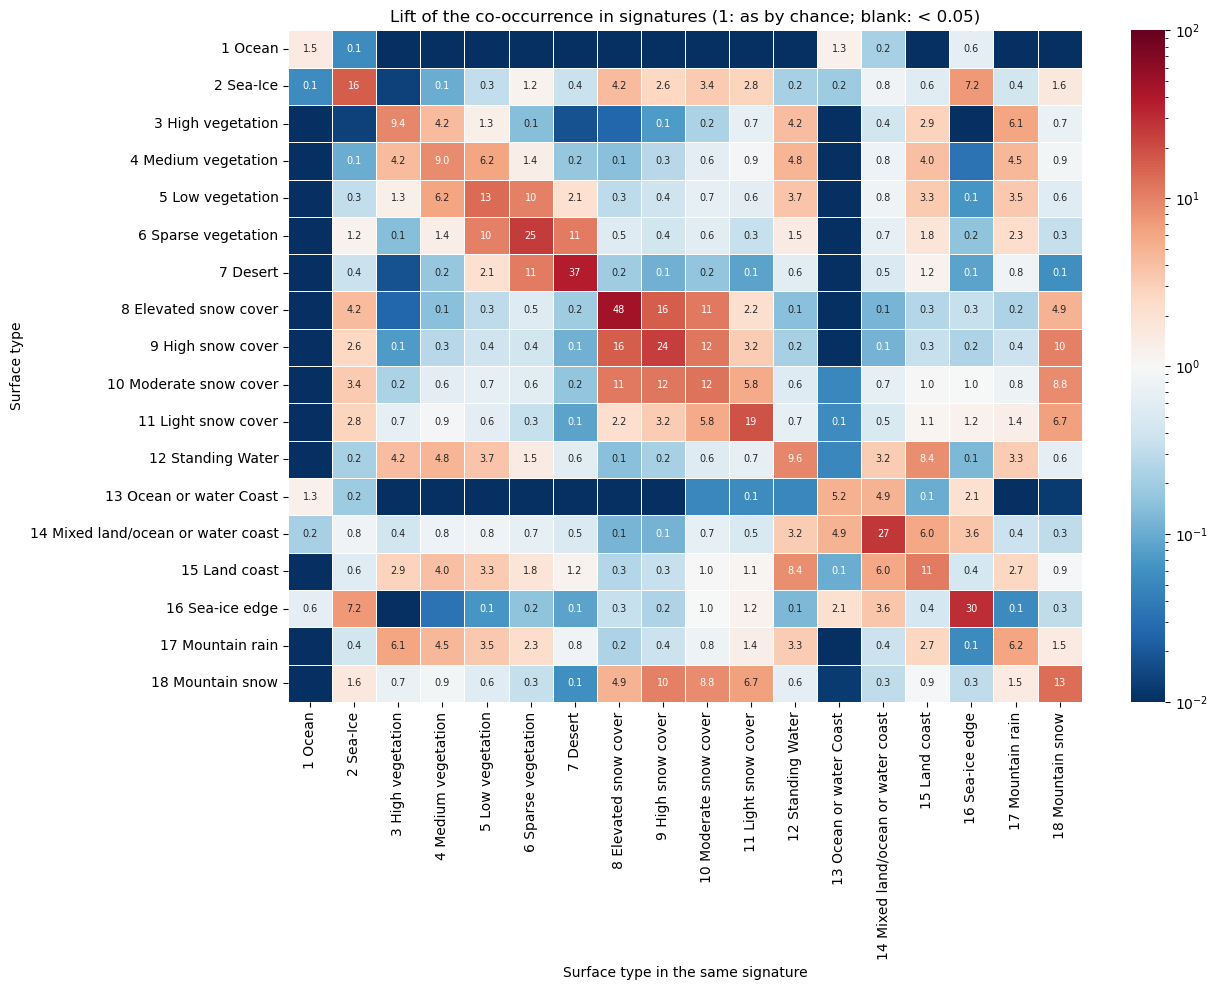

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.colors import LogNorm

from pmw_analysis.constants import ST_COLUMNS

# Signatures × surface types 1..18; the -9999 entries are always 0 and the null ones are left out
n_types = len(ST_COLUMNS)
long = (
    df_b2_non_null.select(pl.int_range(pl.len()).alias("row"), COLUMN_VALUE_COUNTS)
    .explode(COLUMN_VALUE_COUNTS, empty_as_null=True)
    .unnest(COLUMN_VALUE_COUNTS)
    .filter((pl.col(STRUCT_FIELD_COUNT) > 0) & pl.col(VARIABLE_SURFACE_TYPE_INDEX).is_between(1, n_types))
)
counts = np.zeros((df_b2_non_null.height, n_types))
counts[long["row"].to_numpy(), long[VARIABLE_SURFACE_TYPE_INDEX].to_numpy() - 1] = long[STRUCT_FIELD_COUNT].to_numpy()
total_type = counts.sum(axis=0)  # T_t
total = total_type.sum()  # N
total_signature = counts.sum(axis=1)  # N_sig

# Confusion: of the observations of type t (row), the share in signatures whose cluster is k (column)
cluster = df_b2_non_null["cluster"].fill_null(-1).to_numpy()
confusion = np.stack([counts[cluster == k].sum(axis=0) for k in range(1, n_types + 1)], axis=1)
confusion_share = confusion / total_type[:, None]

# Co-occurrence: A[a, b] = Σ_sig n_a · n_b / N_sig
weight = np.divide(1.0, total_signature, out=np.zeros_like(total_signature), where=total_signature > 0)
cooccurrence = (counts * weight[:, None]).T @ counts
# Of the observations in the signature of a type-a observation (row), the share of type b (column);
# the diagonal is type a's precision with cluster = signature
cooccurrence_share = cooccurrence / total_type[:, None]
# Lift: that share relative to type b's share of all observations; > 1 when a and b share signatures more than by chance
lift = cooccurrence * total / np.outer(total_type, total_type)

print(f"P (cluster = signature): {np.trace(cooccurrence) / total:.4f}")
print(f"P (cluster = most frequent type), from the confusion: {(confusion ** 2 / confusion.sum(axis=0)).sum() / total:.4f}")

labels = [f"{idx} {name}" for idx, name in enumerate(ST_COLUMNS, start=1)]


def plot_table(values: np.ndarray, annot: np.ndarray, title: str, xlabel: str, ylabel: str, **kwargs):
    plt.figure(figsize=(13, 10))
    sns.heatmap(values, annot=annot, fmt="", annot_kws={"fontsize": 7}, xticklabels=labels, yticklabels=labels,
                linewidths=0.5, linecolor="white", **kwargs)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.tight_layout()
    plt.show()


def annot_percent(share: np.ndarray) -> np.ndarray:
    # Blank below 0.5 %, i.e. when the rounded percentage would be 0
    return np.vectorize(lambda v: f"{100 * v:.0f}" if 100 * v >= 0.5 else "")(share)


plot_table(100 * confusion_share, annot_percent(confusion_share),
           "Share (%) of the observations of each surface type by the cluster of their signature (blank: < 0.5 %)",
           "Cluster (most frequent surface type of the signature)", "Surface type", cmap="Blues", vmin=0, vmax=100)
plot_table(100 * cooccurrence_share, annot_percent(cooccurrence_share),
           "Share (%) of each surface type among the observations sharing the signature (blank: < 0.5 %)",
           "Surface type in the same signature", "Surface type", cmap="Blues", vmin=0, vmax=100)

LIFT_MAX = 100  # colors saturate beyond 1/100 and 100
plot_table(np.clip(lift, 1 / LIFT_MAX, LIFT_MAX),
           np.vectorize(lambda v: f"{v:.0f}" if v >= 10 else f"{v:.1f}" if v >= 0.05 else "")(lift),
           "Lift of the co-occurrence in signatures (1: as by chance; blank: < 0.05)",
           "Surface type in the same signature", "Surface type",
           cmap="RdBu_r", norm=LogNorm(vmin=1 / LIFT_MAX, vmax=LIFT_MAX))
